# Dummy S1 light collection efficiency map generator

This notebook generates a simple, approximately realistic **S1 light collection efficiency (LCE) map** (also called an S1 *pattern map*) without running an optical photon propagation simulation (e.g. Geant4 or Chroma). Such a map is good enough to test a simulation and processing chain end-to-end, for example for a new detector geometry like XLZD. It is not a replacement for a proper optical simulation.

The map is saved in the format used by [fuse](https://github.com/XENONnT/fuse), the XENONnT simulation framework, which ember reads as well (`ember_map://`). The concepts, however, apply to any xenon TPC, and the notebook is also meant as a tutorial on what such a map has to contain and the terminology and coordinate conventions used.

### What is an S1 LCE map?

Scintillation photons of an S1 signal are emitted isotropically at the interaction point. Only a fraction of them produce a signal in a photosensor: photons are absorbed on the PTFE walls, on electrode wires or in the xenon itself, get reflected at the liquid-gas interface, or miss the photosensors. Photons that reach a PMT are converted into photoelectrons (charge) with the PMT's quantum efficiency (QE), collection efficiency (CE) and double photo electron emission probability ($p_\mathrm{DPE}$). QE, CE and $p_\mathrm{DPE}$ are encoded in the photon gain g1.

The S1 LCE map stores for every position $(x, y, z)$ and every PMT $i$:

$$p_i(x, y, z) = \text{mean number of photoelectrons (PE) in PMT } i \text{ per photon emitted at } (x, y, z)$$

It is a 4D array with shape `(n_x, n_y, n_z, n_PMTs)`. It contains two pieces of information:

* **The sum over all PMTs**, $g_1(x, y, z) = \sum_i p_i(x, y, z)$, is the local photon detection efficiency in PE/photon. It sets how much light an event at this position produces.
* **The relative values between PMTs**, $p_i / \sum_j p_j$, form the hit pattern: which PMTs are likely to see the light. This is used for example by position reconstruction and for the top/bottom split of the S1.

### How ember and fuse use the map

For an interaction emitting $N$ photons at $(x, y, z)$, the plugins `S1PhotonHits` and `S1PhotonPropagation`
1. draws the number of detected photons from a binomial distribution with $p = \sum_i p_i / (1 + p_\mathrm{DPE}) \cdot \epsilon_\mathrm{det}$, where $p_\mathrm{DPE}$ is the double photoelectron emission probability and $\epsilon_\mathrm{det}$ an additional global S1 detection efficiency (usually 1),
2. assigns each detected photon to a PMT with probability $p_i / \sum_j p_j$,
3. lets each detected photon produce one or, with probability $p_\mathrm{DPE}$, two photoelectrons.

Since the plugins divide by $(1 + p_\mathrm{DPE})$ themselves, the map has to be normalized in **PE per emitted photon** ($g_{1,\mathrm{PE}}$), not in phd per emitted photon. PMTs that are switched off (gain 0) are set to zero by the plugins automatically.

### Effects included in this dummy map

1. **Average photon detection efficiency $g_1$.** Averaged over the TPC volume, the map returns the $g_1$ defined below.
2. **Top/bottom asymmetry.** The fraction of light seen by the top and bottom PMT array depends on the depth of the interaction. This does not change the total amount of light, only how it is split between the arrays.
3. **Position dependent light yield.** The total amount of detected light depends on the position: more light is detected near the bottom array and less near the liquid surface and the TPC wall.

The position dependence is based on XENONnT data (taken from a published thesis) and scaled to the size of the detector defined below. The true dependence depends on TPC size, wall reflectivity and photon absorption length. Thus for small TPCs the losses are likely overestimated.

### Limitations

* All PMTs within one array get the same value. A realistic per-PMT hit pattern requires a photon propagation simulation.
* The light yield model is defined between gate and cathode. Below the cathode (down to the bottom PMTs) the values at the cathode are continued. S1s produced in the gas phase get the values at the gate.
* The geometry is a cylindrical, dual-phase TPC with a top and a bottom PMT array (XENON, LZ, XLZD, PandaX). 

### Terminology

| Term | Meaning |
|---|---|
| S1 | Prompt scintillation light signal of an interaction in the liquid xenon. |
| PMT / channel | Photosensor. In the map, every channel has its own entry along the last axis. |
| PE | Photoelectron, the unit in which XENON quotes signal sizes. |
| DPE | Double photoelectron emission: a VUV photon can release two photoelectrons from the PMT photocathode, with probability $p_\mathrm{DPE} \approx 0.2$. |
| phd | Photons detected, i.e. PE corrected for DPE: $\mathrm{phd} = \mathrm{PE} / (1 + p_\mathrm{DPE})$. This is the unit LZ uses. |
| $g_1$ | Photon detection efficiency (here in PE): detected signal per emitted S1 photon. |
| AFT | Area fraction top: fraction of the S1 seen by the top PMT array, $\mathrm{AFT} = S1_\mathrm{top} / S1_\mathrm{total}$. LZ uses the top-bottom asymmetry $\mathrm{TBA} = (T - B)/(T + B) = 2\,\mathrm{AFT} - 1$. |
| Relative light yield (LY$_\mathrm{rel}$) | Light yield at a position divided by the average light yield of the detector. |
| strax / straxen | XENON data processing framework. `straxen.InterpolatingMap` reads and interpolates the map. In ember, `ember.maps.RegularGridMap` does the same. |
| fuse | XENON simulation framework that turns the energy deposits of a Geant4 simulation into simulated raw data. |

### Coordinate conventions

* $x$, $y$ in cm, origin on the TPC axis.
* $z$ in cm, with the convention of ember's `detector.yaml`: $z = 0$ at the gate and negative below it, i.e. the cathode is at $z = -L$. The models below use the **depth** below the gate, $d = z_\mathrm{gate} - z$ (0 at the gate, positive downwards). If your experiment measures $z$ differently (e.g. upwards from the cathode or the bottom array), shift your positions accordingly.
* PMT order: channels `0 ... n_top - 1` are the top array, followed by the bottom array. The order has to match the channel map of the simulation.

## Detector parameters

The detector parameters are read from ember's detector file `ember/config/detector.yaml`, so the map always matches the simulated detector:

* `tpc_radius`, `tpc_length`: radius of the TPC and distance between gate and cathode in cm.
* `z_bottom_pmts`: lower end of the map. The map continues below the cathode down to the bottom PMTs, so that interactions below the cathode also produce light.
* `number_of_pmts_top`, `number_of_pmts_bottom`: number of channels in the top and bottom array. The total must equal the number of channels in the simulation.
* `g1_pe`: average number of photoelectrons per emitted S1 photon, including DPE (`g1` in the detector file). If you know $g_1$ in phd/photon (e.g. from LZ), convert with $g_{1,\mathrm{PE}} = g_{1,\mathrm{phd}} \cdot (1 + p_\mathrm{DPE})$.
* `double_photoelectron_fraction`: DPE probability $p_\mathrm{DPE}$ of the PMTs (`p_double_pe_emission`). It is not used for the map itself, but the plugins use the same value.

The remaining parameters describe the model and are set here:

* `area_fraction_in_top_array_at_liquid_surface`, `area_fraction_in_top_array_at_cathode`: AFT for events just below the gate and just above the cathode.
* `number_of_bins_per_z_slice_in_x_or_y`, `number_of_z_slices`: binning of the map. Values in between bins are interpolated.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import strax

import ember
from ember.maps import encode_map_values, load_map, save_map_data
from ember.url_protocols import DUMMY_MAP_DIRECTORY

In [2]:
tpc_radius = strax.URLConfig.evaluate_dry("detector://tpc_radius")  # cm
z_gate = strax.URLConfig.evaluate_dry("detector://z_gate")  # cm
z_cathode = strax.URLConfig.evaluate_dry("detector://z_cathode")  # cm
z_bottom_pmts = strax.URLConfig.evaluate_dry("detector://z_bottom_pmts")  # cm
tpc_length = z_gate - z_cathode  # cm, between gate and cathode

number_of_pmts_top = strax.URLConfig.evaluate_dry("detector://n_top_pmts")
number_of_pmts_bottom = strax.URLConfig.evaluate_dry("detector://n_bottom_pmts")
total_number_of_pmts = number_of_pmts_top + number_of_pmts_bottom

g1_pe = strax.URLConfig.evaluate_dry("detector://g1")  # pe/photon
double_photoelectron_fraction = strax.URLConfig.evaluate_dry("detector://p_double_pe_emission")
g1_phd = g1_pe / (1 + double_photoelectron_fraction)  # fraction of detected photons per emitted photon

area_fraction_in_top_array_at_liquid_surface = 0.65  # fraction of photons that hit the top array at the liquid surface
area_fraction_in_top_array_at_cathode = 0.1  # fraction of photons that hit the top array at the cathode

number_of_bins_per_z_slice_in_x_or_y = 20
number_of_z_slices = 50

print(f"TPC: R = {tpc_radius} cm, L = {tpc_length} cm, map from z = {z_bottom_pmts} cm to the gate")
print(f"PMTs: {number_of_pmts_top} top, {number_of_pmts_bottom} bottom")
print(f"Average number of photoelectrons per emitted photon (g1_pe): {g1_pe:.5f}")
print(f"Average number of photons detected per emitted photon (g1_phd): {g1_phd:.5f}")

TPC: R = 66.4 cm, L = 148.6515 cm, map from z = -154.6555 cm to the gate
PMTs: 253 top, 241 bottom
Average number of photoelectrons per emitted photon (g1_pe): 0.15100
Average number of photons detected per emitted photon (g1_phd): 0.12387


## Step 1: Average photon detection efficiency $g_1$

Start with a map of ones with shape `(n_x, n_y, n_z, n_PMTs)`. The first three axes are the position bins, the last axis the PMT channels:

In [3]:
dummy_map = np.ones((
    number_of_bins_per_z_slice_in_x_or_y, 
    number_of_bins_per_z_slice_in_x_or_y, 
    number_of_z_slices, 
    total_number_of_pmts), 
    dtype=np.float64
)

Normalize such that at each position every PMT has the same probability to detect a photon. The sum over all PMTs then yields $g_{1,\mathrm{PE}}$ at every position:

In [4]:
dummy_map[:]*=g1_pe/total_number_of_pmts

Check that the sum over all PMTs yields $g_{1,\mathrm{PE}}$ at each position:

In [5]:
dummy_map[:].sum(axis=-1) 

array([[[0.151, 0.151, 0.151, ..., 0.151, 0.151, 0.151],
        [0.151, 0.151, 0.151, ..., 0.151, 0.151, 0.151],
        [0.151, 0.151, 0.151, ..., 0.151, 0.151, 0.151],
        ...,
        [0.151, 0.151, 0.151, ..., 0.151, 0.151, 0.151],
        [0.151, 0.151, 0.151, ..., 0.151, 0.151, 0.151],
        [0.151, 0.151, 0.151, ..., 0.151, 0.151, 0.151]],

       [[0.151, 0.151, 0.151, ..., 0.151, 0.151, 0.151],
        [0.151, 0.151, 0.151, ..., 0.151, 0.151, 0.151],
        [0.151, 0.151, 0.151, ..., 0.151, 0.151, 0.151],
        ...,
        [0.151, 0.151, 0.151, ..., 0.151, 0.151, 0.151],
        [0.151, 0.151, 0.151, ..., 0.151, 0.151, 0.151],
        [0.151, 0.151, 0.151, ..., 0.151, 0.151, 0.151]],

       [[0.151, 0.151, 0.151, ..., 0.151, 0.151, 0.151],
        [0.151, 0.151, 0.151, ..., 0.151, 0.151, 0.151],
        [0.151, 0.151, 0.151, ..., 0.151, 0.151, 0.151],
        ...,
        [0.151, 0.151, 0.151, ..., 0.151, 0.151, 0.151],
        [0.151, 0.151, 0.151, ..., 0.151, 0.1

## Step 2: Asymmetry between top and bottom array

The light is not shared equally between the two arrays. Because of the large difference in refractive index between liquid and gaseous xenon, a large fraction of the photons emitted upwards is totally reflected at the liquid surface. In addition, the solid angle covered by each array depends on the depth. As a result, events close to the gate share their light roughly equally between both arrays, while for events close to the cathode almost all light is seen by the bottom array.

We model the area fraction top (AFT) as a linear function of the depth $d$ below the gate. Below the cathode the AFT at the cathode is used. The light at each depth is redistributed between the arrays without changing its sum: each top PMT receives $\mathrm{AFT} \cdot g_1 / n_\mathrm{top}$ and each bottom PMT $(1 - \mathrm{AFT}) \cdot g_1 / n_\mathrm{bottom}$.

In [6]:
def area_fraction_in_top_array(depth):
    depth = np.clip(depth, 0, tpc_length)  # below the cathode the value at the cathode is continued
    return area_fraction_in_top_array_at_liquid_surface + (area_fraction_in_top_array_at_cathode - area_fraction_in_top_array_at_liquid_surface) * (depth / tpc_length)

position_of_z_slices = np.linspace(z_bottom_pmts, z_gate, number_of_z_slices)  # z of the map grid, increasing
depth_of_z_slices = z_gate - position_of_z_slices
area_fraction_in_top_array_values = area_fraction_in_top_array(depth_of_z_slices)

In [7]:
for z_index, area_fraction in enumerate(area_fraction_in_top_array_values):
    dummy_map[:, :, z_index, :number_of_pmts_top] *= area_fraction/number_of_pmts_top*total_number_of_pmts
    dummy_map[:, :, z_index, number_of_pmts_top:] *= (1 - area_fraction)/number_of_pmts_bottom*total_number_of_pmts

Check that the sum over all PMTs still yields $g_{1,\mathrm{PE}}$ at each position:

In [8]:
dummy_map[0, 0, 0, :].sum()  # This should be equal to g1_pe

np.float64(0.151)

Check that the light fraction seen by the top array follows the AFT model for a given (x, y) bin:

In [9]:
dummy_map[0, 0, :, :number_of_pmts_top].sum(axis=-1)/g1_pe  # This should be equal to area_fraction_in_top_array_values

array([0.1       , 0.1       , 0.10114131, 0.11281916, 0.124497  ,
       0.13617485, 0.14785269, 0.15953054, 0.17120838, 0.18288623,
       0.19456407, 0.20624191, 0.21791976, 0.2295976 , 0.24127545,
       0.25295329, 0.26463114, 0.27630898, 0.28798682, 0.29966467,
       0.31134251, 0.32302036, 0.3346982 , 0.34637605, 0.35805389,
       0.36973174, 0.38140958, 0.39308742, 0.40476527, 0.41644311,
       0.42812096, 0.4397988 , 0.45147665, 0.46315449, 0.47483233,
       0.48651018, 0.49818802, 0.50986587, 0.52154371, 0.53322156,
       0.5448994 , 0.55657725, 0.56825509, 0.57993293, 0.59161078,
       0.60328862, 0.61496647, 0.62664431, 0.63832216, 0.65      ])

## Step 3: Position dependent light yield

So far the total amount of detected light is the same everywhere. In a real TPC it depends on the position of the interaction:

* **Depth:** photons emitted close to the bottom array have a high chance to reach it directly. Photons emitted close to the liquid surface are often reflected at the surface and travel longer paths, with more chances to be absorbed on the walls, on the electrodes or in the xenon. Hence more light is detected from the bottom of the TPC.
* **Radius:** close to the wall, more photons hit the PTFE reflectors, which do not reflect 100 %, so less light is detected.

In data, this dependence is measured with calibration sources that are distributed uniformly in the TPC and produce a mono-energetic line, e.g. $^{83m}\mathrm{Kr}$ . In data processing, the S1 is divided by this relative light yield to obtain the position corrected S1.

We assume a simple model for the relative light yield. For the dependence on the depth $z$ below the gate (in cm, XENONnT dimensions):

$$\mathrm{LY_{rel}}(z) \approx 0.878 + 1.42\times10^{-3}\,z + 4.09\times10^{-5}\,z^2$$

In addition the radial component is modeled via:

$$\mathrm{LY_{rel}}(r,z) \approx \mathrm{LY_{rel}}(z)\,\left[1 - 0.11\,(r/R)^2\right]$$

where $R$ is the TPC radius. The model is based on the data shown in the thesis: "Extending the Nuclear Recoil Calibration Down to the Single-Photon Level for the XENONnT Experiment" by Johanna Jakob. The model itself was extracted by Claude.

To use the model for a TPC of a different size, $z$ is scaled with the TPC length and $r$ with the TPC radius. This assumes that the shape of the light yield map is the same as in XENONnT, which is only a rough approximation.

Define the relative light yield model. For radii outside the TPC (the corners of the square x-y grid, see below) the value at the wall is used, and below the cathode the value at the cathode:

In [10]:
def rel_ly_yield(Z, R, R_max, Z_max):
    """
    Calculate the relative light yield as a function of position in the TPC.

    Args:
        Z (float): The depth below the gate (in cm).
        R (float): The radial coordinate in the TPC (in cm).
        R_max (float): The maximum radial coordinate in the TPC (in cm).
        Z_max (float): The length of the TPC between gate and cathode (in cm).
    """    
    z = np.clip(Z, 0, Z_max)/Z_max*150 # Below the cathode the value at the cathode is used. Since XENONnT is used as reference, we need to scale the z-coordinate to match the XENONnT TPC length of 150 cm.
    rel_yield_z = 0.878 + 1.42*10**(-3)*z + 4.09*10**(-5)*z**2
    r = np.clip(R, 0, R_max) # To avoid unphysical values outside of the TPC, we limit the radial coordinate to the maximum radius of the TPC.
    rel_yield_r = 1 - 0.11*(r/R_max)**2
    
    return rel_yield_z * rel_yield_r

In [11]:
RZ = np.meshgrid(np.linspace(0, 150, 150), np.linspace(0, 67, 67))
rel_ly = rel_ly_yield(RZ[0], RZ[1], 67, 150)

Text(0, 0.5, 'Z [cm]')

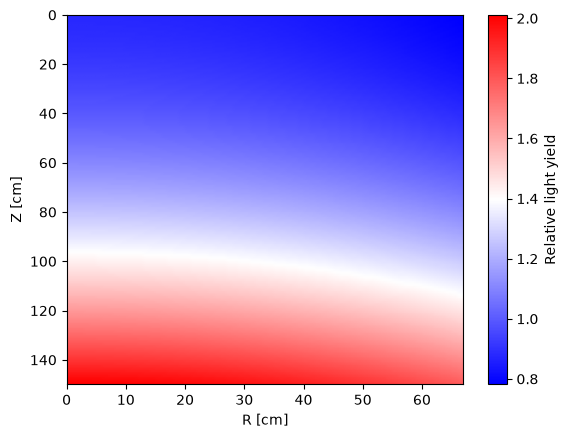

In [12]:
plt.imshow(rel_ly.T, extent=[0, 67, 150, 0], aspect='auto', cmap='bwr')
plt.colorbar(label='Relative light yield')
plt.xlabel('R [cm]')
plt.ylabel('Z [cm]')

The plot above shows the model in XENONnT dimensions (R = 67 cm, L = 150 cm). Scaled to an XLZD-like detector size it looks like:

Text(0, 0.5, 'Z [cm]')

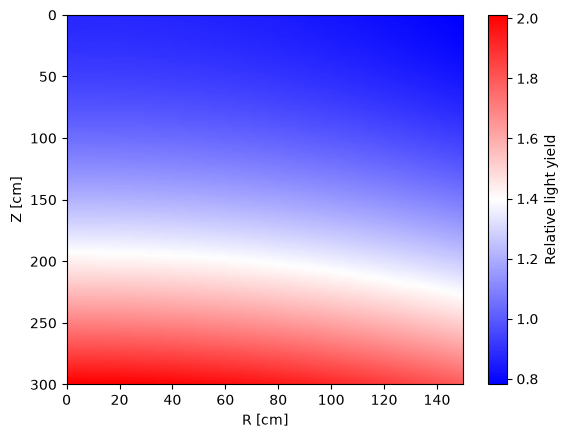

In [13]:
RZ = np.meshgrid(np.linspace(0, 300, 150), np.linspace(0, 150, 67))
rel_ly = rel_ly_yield(RZ[0], RZ[1], 150, 300)

plt.imshow(rel_ly.T, extent=[0, 150, 300, 0], aspect='auto', cmap='bwr')
plt.colorbar(label='Relative light yield')
plt.xlabel('R [cm]')
plt.ylabel('Z [cm]')

In data processing, the inverse of this map is used for the S1 position correction. For the simulation, however, we need the effect itself: the map from step 2 is multiplied with the relative light yield.

Every PMT entry at a given position is weighted with the same factor. This keeps the top/bottom split from step 2 and only changes the total amount of light. Some details:

* The relative light yield is normalized to a mean of 1 inside the TPC (between gate and cathode), so that the map still returns $g_{1,\mathrm{PE}}$ when averaged over the volume. The slices below the cathode are excluded from the normalization.
* The map uses a square x-y grid, but the TPC is a cylinder. About 25 % of the x-y bins lie in the corners outside the TPC ($r > R$). No events happen there, but these bins are used when interpolating close to the wall. They get the value at the wall (see `np.clip` in `rel_ly_yield`) and are excluded from the normalization.

In [14]:
# indexing='ij' keeps the axis order (x, y, z) of dummy_map; the default 'xy' would swap x and y
X, Y, Z = np.meshgrid(
    np.linspace(-tpc_radius, tpc_radius, number_of_bins_per_z_slice_in_x_or_y),
    np.linspace(-tpc_radius, tpc_radius, number_of_bins_per_z_slice_in_x_or_y),
    position_of_z_slices,
    indexing='ij'
)
R = np.sqrt(X**2 + Y**2)
depth = z_gate - Z

rel_ly_xyz = rel_ly_yield(depth, R, tpc_radius, tpc_length)  # shape (x, y, z)

# Normalize to a mean of 1 inside the TPC so the map still yields g1_pe on average.
# Bins in the corners of the square grid (R > tpc_radius) and below the cathode are excluded from the mean.
inside_tpc = (R <= tpc_radius) & (Z >= z_cathode)
rel_ly_xyz /= rel_ly_xyz[inside_tpc].mean()

# Weight every PMT entry at a given position by the same relative light yield
dummy_map *= rel_ly_xyz[..., np.newaxis]

In [15]:
np.allclose(dummy_map.sum(axis=-1)/g1_pe, rel_ly_xyz)  # Summed over all PMTs, the map should now follow the relative light yield

True

In [16]:
dummy_map.sum(axis=-1)[inside_tpc].mean()  # This should be equal to g1_pe

np.float64(0.151)

## Save the map in the fuse format

The map is stored as a pickled dictionary in the format of fuse, which ember's `ember_map://` protocol (and `straxen.InterpolatingMap`) can read. The file contains the following keys:

| Key | Content |
|---|---|
| `coordinate_system` | Grid of the map as `[name, (min, max, n_points)]` for x, y and z in cm. The grid points are `np.linspace(min, max, n_points)`, i.e. they must be evenly spaced and increasing. |
| `map` | The map values with shape `(n_x, n_y, n_z, n_PMTs)` in PE per emitted photon. |
| `quantized` | The values are stored as integers in units of this number (here $10^{-6}$) to reduce the file size. |
| `compressed` | Compressor, integer type and shape of the compressed `map` (zstd, uint32). |
| `name`, `description`, `timestamp` | Metadata. |

The map is saved to `ember/dummy_maps/s1_pattern_map_dummy.pkl`, the default of the option `s1_pattern_map` of the ember plugins `S1PhotonHits` and `S1PhotonPropagation`. The number of channels in the map must match `n_tpc_pmts` of the detector file.

If you want to use a map from your own optical simulation (e.g. from another experiment), fill an array of the same shape in PE per emitted photon and save it the same way. Then either overwrite this file (and delete stored simulation data, since strax does not notice the change) or point `s1_pattern_map` to your file.

In [17]:
import time

lce_map = {
    'coordinate_system': [
        ['x', (-float(tpc_radius), float(tpc_radius), number_of_bins_per_z_slice_in_x_or_y)],
        ['y', (-float(tpc_radius), float(tpc_radius), number_of_bins_per_z_slice_in_x_or_y)],
        ['z', (float(z_bottom_pmts), float(z_gate), number_of_z_slices)],
    ],
    'description': (
        f'Dummy S1 LCE per-PMT map for a TPC with R={tpc_radius} cm, L={tpc_length} cm and '
        f'{number_of_pmts_top} top / {number_of_pmts_bottom} bottom PMTs. '
        f'Average g1={g1_pe:.5f} pe/photon (including double photoelectron emission), top/bottom asymmetry and relative light yield based on XENONnT data. '
        f'Below the cathode (down to z={z_bottom_pmts} cm) the values at the cathode are continued.'
    ),
    'timestamp': time.time(),
    'name': 'Dummy S1 LCE per-PMT map',
    'map': dummy_map,
}

output_file = DUMMY_MAP_DIRECTORY / 's1_pattern_map_dummy.pkl'
save_map_data(encode_map_values(lce_map, quantized=1e-6), output_file)
print('Saved', output_file)

Saved /mnt/d/XLZD/mymodules/ember/ember/dummy_maps/s1_pattern_map_dummy.pkl


Now load the saved map with ember and check the result. Summed over all PMTs and divided by $g_{1,\mathrm{PE}}$, the map should return the relative light yield. Note that with an even number of bins there is no grid point at $x = y = 0$, so the interpolated values deviate slightly from the model:

In [18]:
itp_map = load_map(output_file)

# Sum over all PMTs at the center of the TPC, just below the gate, at half depth, just above the cathode
# and below the cathode. Should be equal to the relative light yield at these positions.
test_positions = np.array([[0, 0, -1], [0, 0, -tpc_length/2], [0, 0, z_cathode + 1], [0, 0, z_cathode - 3]])
itp_map(test_positions).sum(axis=-1)/g1_pe

array([0.71780572, 0.99142667, 1.63112048, 1.64211921])

In [19]:
# Light fraction seen by the top array at the same positions (AFT)
values = itp_map(test_positions)
values[:, :number_of_pmts_top].sum(axis=-1) / values.sum(axis=-1)

array([0.64668685, 0.37501161, 0.10371894, 0.09999193])

## Optional: light collection from the optical toy Monte Carlo

The map above is built from a parametrization of XENONnT data. A second way to get the position dependence is to track photons through the detector. ember's **optical toy Monte Carlo** (`ember.optical_toy_mc`), which also builds the S1 timing map (see `dummy_s1_timing_maps.ipynb`), tracks single photons through a cylindrical TPC: Rayleigh scattering and absorption in the xenon, diffuse reflection on the PTFE walls, Fresnel reflection and total internal reflection at the liquid surface, and PMT arrays that are covered by photocathodes with the fraction $n_\mathrm{PMT} (d/2)^2 / R^2$. The optical parameters are read from `detector.yaml`. They are the best-fit values of K. Böse, PhD thesis, Heidelberg University (2026), Table 4.9.

For a photon emitted at $(r, z)$, the Monte Carlo gives the probability to reach a photocathode of the top or the bottom array, the light collection efficiency $\mathrm{LCE}_\mathrm{top}(r, z)$ and $\mathrm{LCE}_\mathrm{bottom}(r, z)$. The Monte Carlo does not know the quantum and collection efficiencies of the PMTs. We therefore scale the LCE such that its average inside the TPC equals $g_{1,\mathrm{PE}}$, as for the dummy map. Only the **shape** of the position dependence is compared. Böse calls this a "normalized $g_1$".

This section does not change the saved map. It takes about a minute.

In [20]:
from scipy.interpolate import RegularGridInterpolator

from ember.optical_toy_mc import OUTCOME_BOTTOM, OUTCOME_TOP, TpcOptics, simulate_photons

optics = TpcOptics.from_detector_config()
print(optics)

TpcOptics(tpc_radius=66.4, z_bottom_pmts=-154.6555, z_liquid_level=0.5116, z_top_pmts=7.3936, lxe_refractive_index=1.63, lxe_rayleigh_scattering_length=32.0, lxe_absorption_length=1245.0, gxe_absorption_length=1245.0, ptfe_reflectivity_liquid=1.0, ptfe_reflectivity_gas=0.8013, photocathode_coverage_top=0.5876034257511975, photocathode_coverage_bottom=0.5597329075337494)


The photons are emitted on a grid of radii and the z slices of the map. The radii are chosen such that each one represents the same area of the cross section, so a simple mean over the radii is an average over the area. At each grid point the photons start at random azimuthal angles.

In [21]:
number_of_radii = 8
photons_per_grid_point = 10_000
radii_of_toy_mc = tpc_radius * np.sqrt((np.arange(number_of_radii) + 0.5) / number_of_radii)

lce_top = np.zeros((number_of_radii, number_of_z_slices))
lce_bottom = np.zeros((number_of_radii, number_of_z_slices))
rng = np.random.default_rng(0)
for r_index, radius in enumerate(radii_of_toy_mc):
    for z_index, z in enumerate(position_of_z_slices):
        phi = 2 * np.pi * rng.random(photons_per_grid_point)
        start_positions = np.column_stack(
            [radius * np.cos(phi), radius * np.sin(phi), np.full(photons_per_grid_point, z)]
        )
        photons = simulate_photons(start_positions, optics, seed=r_index * number_of_z_slices + z_index)
        lce_top[r_index, z_index] = np.mean(photons["outcome"] == OUTCOME_TOP)
        lce_bottom[r_index, z_index] = np.mean(photons["outcome"] == OUTCOME_BOTTOM)

lce_total = lce_top + lce_bottom
is_above_cathode = position_of_z_slices >= z_cathode
print(f"Mean LCE inside the TPC: {lce_total[:, is_above_cathode].mean():.3f}")

Mean LCE inside the TPC: 0.533


Scale the LCE to $g_{1,\mathrm{PE}}$ inside the TPC. The factor is the product of quantum efficiency, collection efficiency and DPE that the Monte Carlo does not model:

In [22]:
efficiency_scale = g1_pe / lce_total[:, is_above_cathode].mean()
toy_g1_top = lce_top * efficiency_scale
toy_g1_bottom = lce_bottom * efficiency_scale
print(f"Scale factor (QE x CE x (1 + p_DPE)): {efficiency_scale:.3f}")

Scale factor (QE x CE x (1 + p_DPE)): 0.283


### Comparison of the two models

Compare the toy Monte Carlo with the dummy map saved above (`itp_map`) along the TPC axis, along the radius at mid depth, and for the AFT:

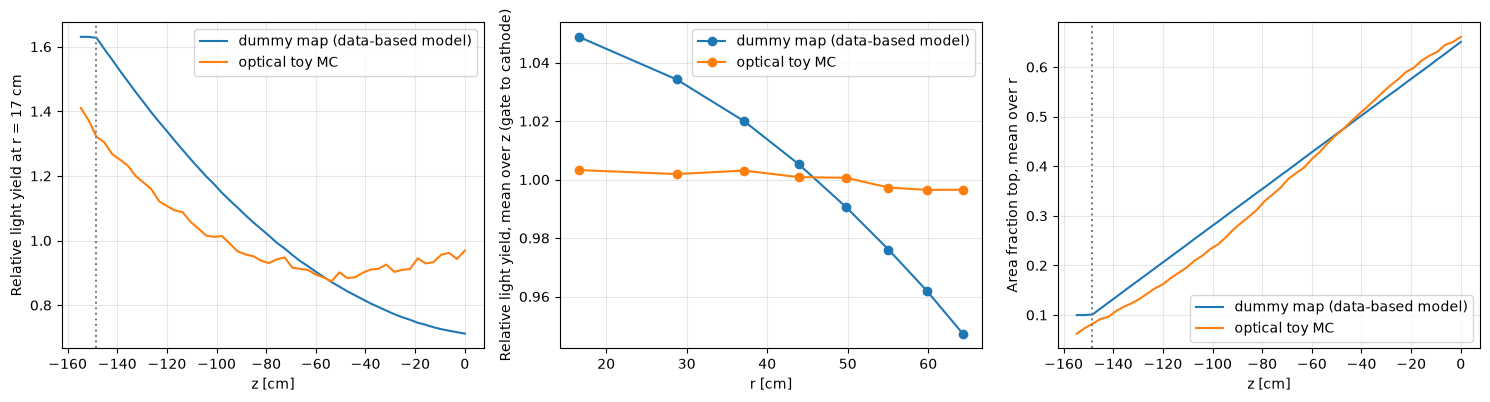

In [23]:
radius_grid, z_grid = np.meshgrid(radii_of_toy_mc, position_of_z_slices, indexing="ij")
positions_in_r_and_z = np.column_stack([radius_grid.ravel(), np.zeros(radius_grid.size), z_grid.ravel()])
dummy_values = itp_map(positions_in_r_and_z).reshape(number_of_radii, number_of_z_slices, -1)
dummy_g1_top = dummy_values[..., :number_of_pmts_top].sum(axis=-1)
dummy_g1_total = dummy_values.sum(axis=-1)
toy_g1_total = toy_g1_top + toy_g1_bottom

figure, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(position_of_z_slices, dummy_g1_total[0] / g1_pe, label="dummy map (data-based model)")
axes[0].plot(position_of_z_slices, toy_g1_total[0] / g1_pe, label="optical toy MC")
axes[0].axvline(z_cathode, color="gray", linestyle=":")
axes[0].set_xlabel("z [cm]")
axes[0].set_ylabel(f"Relative light yield at r = {radii_of_toy_mc[0]:.0f} cm")

axes[1].plot(radii_of_toy_mc, dummy_g1_total[:, is_above_cathode].mean(axis=1) / g1_pe, marker="o", label="dummy map (data-based model)")
axes[1].plot(radii_of_toy_mc, toy_g1_total[:, is_above_cathode].mean(axis=1) / g1_pe, marker="o", label="optical toy MC")
axes[1].set_xlabel("r [cm]")
axes[1].set_ylabel("Relative light yield, mean over z (gate to cathode)")

axes[2].plot(position_of_z_slices, dummy_g1_top.mean(axis=0) / dummy_g1_total.mean(axis=0), label="dummy map (data-based model)")
axes[2].plot(position_of_z_slices, toy_g1_top.mean(axis=0) / toy_g1_total.mean(axis=0), label="optical toy MC")
axes[2].axvline(z_cathode, color="gray", linestyle=":")
axes[2].set_xlabel("z [cm]")
axes[2].set_ylabel("Area fraction top, mean over r")

for axis in axes:
    axis.grid(alpha=0.3)
    axis.legend()
plt.tight_layout()
plt.show()

Things to note (the dotted line marks the cathode):

* **Depth.** Both models detect more light at the bottom than at the top of the TPC, but the toy Monte Carlo is much flatter. Between $z = -140$ cm and $z = -20$ cm the light yield drops by a factor of about 2.0 in the dummy model and about 1.35 in the toy Monte Carlo. XENONnT's $^{83m}$Kr data in Böse's thesis (Fig. 4.4, $g_1^\mathrm{top} + g_1^\mathrm{bottom}$) lie in between, at about 1.6. Böse's SR1 parameter set (Table 4.4) gives almost the same shape in the toy Monte Carlo, so the difference comes from what the toy Monte Carlo leaves out (e.g. the electrodes), not from the parameter choice. Below the cathode the dummy map continues the value at the cathode, while the toy Monte Carlo keeps rising towards the bottom PMTs.
* **Radius.** The PTFE in the liquid reflects 100 % of the light in Böse's timing parameter set, so in the toy Monte Carlo photons are not lost on the wall and the light yield is flat in $r$. The data-based model drops by about 10 % towards the wall.
* **AFT.** Both agree within about 0.03. The toy Monte Carlo gets the AFT from the geometry and the optics alone, the dummy map uses a straight line fixed at the gate and the cathode.

The data-based dummy map therefore stays the default S1 LCE map. The toy Monte Carlo is useful as a cross-check, and as a starting point for a detector geometry without data.

### Optional: build a map from the toy Monte Carlo

The toy Monte Carlo values can be turned into a map in the same format as the dummy map. As before, all PMTs of one array get the same value. Grid points in the corners of the square x-y grid ($r > R$) get the value of the outermost simulated radius.

In [24]:
def interpolate_in_r_and_z(values):
    interpolator = RegularGridInterpolator((radii_of_toy_mc, position_of_z_slices), values)
    clipped_radius = np.clip(R, radii_of_toy_mc[0], radii_of_toy_mc[-1])
    return interpolator(np.stack([clipped_radius, Z], axis=-1))


toy_mc_map = np.zeros_like(dummy_map)
toy_mc_map[..., :number_of_pmts_top] = (interpolate_in_r_and_z(toy_g1_top) / number_of_pmts_top)[..., np.newaxis]
toy_mc_map[..., number_of_pmts_top:] = (interpolate_in_r_and_z(toy_g1_bottom) / number_of_pmts_bottom)[..., np.newaxis]

print("Shape:", toy_mc_map.shape)
print(f"Mean g1 inside the TPC: {toy_mc_map.sum(axis=-1)[inside_tpc].mean():.4f} PE/photon (g1_pe = {g1_pe})")

Shape: (20, 20, 50, 494)
Mean g1 inside the TPC: 0.1510 PE/photon (g1_pe = 0.151)


To use this map in the simulation, save it under a new name and point the option `s1_pattern_map` of the plugins `S1PhotonHits` and `S1PhotonPropagation` to it:

```python
toy_mc_lce_map = dict(lce_map, map=toy_mc_map, name="S1 LCE map from the optical toy Monte Carlo")
save_map_data(encode_map_values(toy_mc_lce_map, quantized=1e-6), DUMMY_MAP_DIRECTORY / "s1_pattern_map_toy_mc.pkl")

context.set_config({"s1_pattern_map": "ember_map://s1_pattern_map_toy_mc.pkl"})
```